# MUSIC-FSL TUTORIAL

## IMPORTS

In [1]:
from typing import Tuple
from collections import defaultdict

import numpy as np
import mirdata

import music_fsl.util as util
from music_fsl.util import widget

In [2]:
dataset = mirdata.initialize('tinysol')
dataset.download()

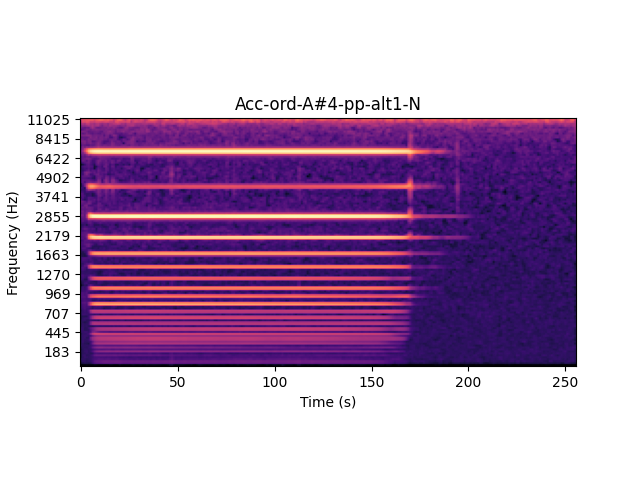

(None, None)

<Figure size 640x480 with 0 Axes>

In [3]:
example_track = dataset.choice_track()
widget(example_track.audio_path)

## CLASS-CONDITIONAL DATASET

In [4]:
import torch
from typing import List, Dict, Any

class ClassConditionalDataset(torch.utils.data.Dataset):
    
    def __getitem__(self, index: int) -> Dict[Any, Any]:
        """
        Grab an item from the dataset. The item returned must be a dictionary. 
        """
        raise NotImplementedError
    
    @property
    def classlist(self) -> List[str]:
        """
        The classlist property returns a list of class labels available in the dataset.
        This property enables users of the dataset to easily access a list of all the classes in the dataset.

        Returns:
            List[str]: A list of class labels available in the dataset. 
        """
        raise NotImplementedError   

    @property
    def class_to_indices(self) -> Dict[str, List[int]]:
        """
        Returns a dictionary where the keys are class labels and the values are 
        lists of indices in the dataset that belong to that class. 
        This property enables users of the dataset to easily access 
        examples that belong to specific classes. 

        Implement me!

        Returns:
            Dict[str, List[int]]: A dictionary mapping class labels to lists of dataset indices. 
        """
        raise NotImplementedError

### TinySOL DATASET

In [5]:
class TinySOL(ClassConditionalDataset):
    """
    Initialize a `TinySOL` dataset instance.

    Args:
        instruments (List[str]): A list of instruments to include in the dataset.
        duration (float): The duration of each audio clip in the dataset (in seconds).
        sample_rate (int): The sample rate of the audio clips in the dataset (in Hz).
    """

    INSTRUMENTS = [
        'Bassoon', 'Viola', 'Trumpet in C', 'Bass Tuba',
        'Alto Saxophone', 'French Horn', 'Violin', 
        'Flute', 'Contrabass', 'Trombone', 'Cello', 
        'Clarinet in Bb', 'Oboe', 'Accordion'
    ]

    def __init__(self,
            instruments: List[str] = None,
            duration: float = 1.0,
            sample_rate: int = 16000,
        ):
        # use all instruments if none are specified
        if instruments is None:
            instruments = self.INSTRUMENTS
        
        self.instruments = instruments
        self.duration = duration
        self.sample_rate = sample_rate

        # initialize the tinysol dataset and download if necessary
        self.dataset = mirdata.initialize('tinysol')
        self.dataset.download()

        # make sure the instruments passed in are valid
        for instrument in instruments:
            assert instrument in self.INSTRUMENTS, f"{instrument} is not a valid instrument"
        
        # load all tracks for this instrument
        self.tracks = []
        for track in self.dataset.load_tracks().values():
            if track.instrument_full in self.instruments:
                self.tracks.append(track)
    
    @property
    def classlist(self) -> List[str]:
        return self.instruments

    @property
    def class_to_indices(self) -> Dict[str, List[int]]:
        # cache it in self._class_to_indices
        # so we don't have to recompute it every time
        if not hasattr(self, "_class_to_indices"):
            # defaultdict -> creates empty default value for each key. Avoids KeyError by returning empty list
            self._class_to_indices = defaultdict(list)
            for i, track in enumerate(self.tracks):
                self._class_to_indices[track.instrument_full].append(i)
        
        return self._class_to_indices

    def __getitem__(self, index) -> Dict:
        # load the track for this index
        track = self.tracks[index]

        # load the excerpt
        data = util.load_excerpt(track.audio_path, self.duration, self.sample_rate)
        data["label"] = track.instrument_full

        return data

    def __len__(self) -> int:
        return len(self.tracks)

In [6]:
dataset = TinySOL()

print(f"The dataset has {len(dataset)} examples.")
print(f"The dataset has {len(dataset.classlist)} classes.\n")

# print the number of examples for each class
for instrument, indices in dataset.class_to_indices.items():
    print(f"{instrument} has {len(indices)} examples")

The dataset has 2913 examples.
The dataset has 14 classes.

Bass Tuba has 108 examples
French Horn has 134 examples
Trombone has 117 examples
Trumpet in C has 96 examples
Accordion has 689 examples
Cello has 291 examples
Contrabass has 309 examples
Viola has 309 examples
Violin has 284 examples
Alto Saxophone has 99 examples
Bassoon has 126 examples
Clarinet in Bb has 126 examples
Flute has 118 examples
Oboe has 107 examples


## SAMPLING FEW-SHOT LEARNING EPISODES

In [7]:
import random

import torch

from music_fsl.data import ClassConditionalDataset
import music_fsl.util as util

In [8]:
class EpisodeDataset(torch.utils.data.Dataset):
    """
        A dataset for sampling few-shot learning tasks from a class-conditional dataset.

    Args:
        dataset (ClassConditionalDataset): The dataset to sample episodes from.
        n_way (int): The number of classes to sample per episode.
            Default: 5.
        n_support (int): The number of samples per class to use as support.
            Default: 5.
        n_query (int): The number of samples per class to use as query.
            Default: 20.
        n_episodes (int): The number of episodes to generate.
            Default: 100.
    """
    def __init__(self,
        dataset: ClassConditionalDataset,
        n_way: int = 5,
        n_support: int = 5,
        n_query: int = 20,
        n_episodes: int = 100,
    ):
        self. dataset = dataset
        self.n_way = n_way
        self.n_support = n_support
        self.n_query = n_query
        self.n_episodes = n_episodes

    def __getitem__(self, index: int) -> Tuple[Dict, Dict]:
        """Sample an episode from the class-conditional dataset."""
        # Seed with index so that for each index, the same episode is sampled.
        rng = random.Random(index)
        
        # sample the list of classes for this episode
        episode_classlist = rng.sample(self.dataset.classlist, self.n_way)

        # sample the support and query sets for the episode
        support, query = [], []
        for c in episode_classlist:
            all_indices = self.dataset.class_to_indices[c]

            # sample the support and query sets for this class
            indices = rng.sample(all_indices, self.n_support + self.n_query)
            items = [self.dataset[i] for i in indices]

            # add the class label to each item
            for item in items:
                item["target"] = torch.tensor(episode_classlist.index(c))

            # split the support and query sets
            support.extend(items[:self.n_support])
            query.extend(items[self.n_support:]) 

        # collate the support and query sets
        support = util.collate_list_of_dicts(support)
        query = util.collate_list_of_dicts(query)

        support["classlist"] = episode_classlist
        query["classlist"] = episode_classlist
        
        return support, query

    def __len__(self):
        return self.n_episodes

    def print_episode(self, support, query):
        """Print a summary of the support and query sets for an episode.

        Args:
            support (Dict[str, Any]): The support set for an episode.
            query (Dict[str, Any]): The query set for an episode.
        """
        print("Support Set:")
        print(f"  Classlist: {support['classlist']}")
        print(f"  Audio Shape: {support['audio'].shape}")
        print(f"  Target Shape: {support['target'].shape}")
        print()
        print("Query Set:")
        print(f"  Classlist: {query['classlist']}")
        print(f"  Audio Shape: {query['audio'].shape}")
        print(f"  Target Shape: {query['target'].shape}")

In [9]:
%%capture
from music_fsl.data import TinySOL

dataset = TinySOL()

# create an episodic dataset
episodes = EpisodeDataset(
    dataset,
    n_way=5, 
    n_support=5,
    n_query=20,
    n_episodes=100,
)

support, query = episodes[0]

In [10]:
episodes.print_episode(support, query)

Support Set:
  Classlist: ['Accordion', 'Violin', 'Oboe', 'Bassoon', 'Alto Saxophone']
  Audio Shape: torch.Size([25, 1, 16000])
  Target Shape: torch.Size([25])

Query Set:
  Classlist: ['Accordion', 'Violin', 'Oboe', 'Bassoon', 'Alto Saxophone']
  Audio Shape: torch.Size([100, 1, 16000])
  Target Shape: torch.Size([100])


## BUILDING A PROTOTYPICAL NETWORK

In [11]:
from music_fsl.backbone import Backbone
import torch

In [12]:
sample_rate = 16000
backbone = Backbone(sample_rate)

print(backbone)

Backbone(
  (melspec): MelSpectrogram(
    (spectrogram): Spectrogram()
    (mel_scale): MelScale()
  )
  (conv1): ConvBlock(
    (conv): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (gn): GroupNorm(8, 32, eps=1e-05, affine=True)
    (relu): ReLU()
    (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): ConvBlock(
    (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (gn): GroupNorm(16, 64, eps=1e-05, affine=True)
    (relu): ReLU()
    (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): ConvBlock(
    (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (gn): GroupNorm(32, 128, eps=1e-05, affine=True)
    (relu): ReLU()
    (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv4): ConvBlock(
    (conv): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (gn

In [13]:
class PrototypicalNet(torch.nn.Module):

    def __init__(self, backbone: torch.nn.Module):
        super().__init__()
        self.backbone = backbone
    
    def forward(self, support: dict, query: dict):
        """
        Forward pass through the protonet. 

        Args:
            support (dict): A dictionary containing the support set. 
                The support set dict must contain the following keys:
                    - audio: A tensor of shape (n_support, n_channels, n_samples)
                    - label: A tensor of shape (n_support) with label indices
                    - classlist: A tensor of shape (n_classes) containing the list of classes in this episode
            query (dict): A dictionary containing the query set.
                The query set dict must contain the following keys:
                    - audio: A tensor of shape (n_query, n_channels, n_samples)
        
        Returns:
            logits (torch.Tensor): A tensor of shape (n_query, n_classes) containing the logits

        After the forward pass, the support dict is updated with the following keys:
            - embeddings: A tensor of shape (n_support, n_features) containing the embeddings
            - prototypes: A tensor of shape (n_classes, n_features) containing the prototypes
        
        The query dict is updated with
            - embeddings: A tensor of shape (n_query, n_features) containing the embeddings

        """
        # compute the embeddings for the support and query sets
        support["embeddings"] = self.backbone(support["audio"])
        query["embeddings"] = self.backbone(query["audio"])

        # group the support embeddings by class
        support_embeddings = []
        for idx in range(len(support["classlist"])):
            embeddings = support["embeddings"][support["target"] == idx]
            support_embeddings.append(embeddings)
        support_embeddings = torch.stack(support_embeddings)

        # compute the prototypes for each class
        prototypes = support_embeddings.mean(dim=1)
        support["prototypes"] = prototypes

        # compute the distances between each query and prototype
        distances = torch.cdist(
            query["embeddings"].unsqueeze(0), 
            prototypes.unsqueeze(0),
            p=2
        ).squeeze(0)

        # square the distances to get the sq euclidean distance
        distances = distances ** 2
        logits = -distances

        # return the logits
        return logits

In [14]:
%%capture
from music_fsl.data import TinySOL, EpisodeDataset

sample_rate = 16000

# create a class-conditional dataset
dataset = TinySOL(sample_rate=sample_rate)

# create an episodic sampler
episodes = EpisodeDataset(
    dataset,
    n_way=5, 
    n_support=5,
    n_query=20,
    n_episodes=100,
)

support, query = episodes[0]

In [15]:
episodes.print_episode(support, query)

Support Set:
  Classlist: ['Accordion', 'Violin', 'Oboe', 'Bassoon', 'Alto Saxophone']
  Audio Shape: torch.Size([25, 1, 16000])
  Target Shape: torch.Size([25])

Query Set:
  Classlist: ['Accordion', 'Violin', 'Oboe', 'Bassoon', 'Alto Saxophone']
  Audio Shape: torch.Size([100, 1, 16000])
  Target Shape: torch.Size([100])


In [16]:
# create our backbone model
backbone = Backbone(sample_rate)

# create a prototypical net
protonet = PrototypicalNet(backbone)

# compute the logits for the sample episode
logits = protonet(support, query)
print(f"got logits with shape {logits.shape}")

got logits with shape torch.Size([100, 5])


## TRAINING A FEW-SHOT INSTRUMENT CLASSIFIER

In [17]:
import torch
import numpy as np
from torch import nn
import pytorch_lightning as pl
from torchmetrics import Accuracy

from music_fsl.backbone import Backbone
from music_fsl.data import TinySOL, EpisodeDataset
from music_fsl.protonet import PrototypicalNet

In [18]:
sample_rate = 16000 # sample rate of the audio
n_way= 5 # number of classes per episode
n_support = 5 # number of support examples per class
n_query = 20 # number of samples per class to use as query
n_train_episodes = int(50000) # number of episodes to generate for training
n_val_episodes = 100 # number of episodes to generate for validation
num_workers = 10 # number of workers to use for data loading

In [19]:
TRAIN_INSTRUMENTS = [
    'French Horn', 
    'Violin', 
    'Flute', 
    'Contrabass', 
    'Trombone', 
    'Cello', 
    'Clarinet in Bb', 
    'Oboe',
    'Accordion'
]

TEST_INSTRUMENTS = [
    'Bassoon',
    'Viola',
    'Trumpet in C',
    'Bass Tuba',
    'Alto Saxophone'
]

In [20]:
# initialize the datasets
train_data = TinySOL(
    instruments=TRAIN_INSTRUMENTS, 
    sample_rate=sample_rate
)

val_data = TinySOL(
    instruments=TEST_INSTRUMENTS, 
    sample_rate=sample_rate
)

In [21]:
# initialize the episode datasets
train_episodes = EpisodeDataset(
    dataset=train_data, 
    n_way=n_way, 
    n_support=n_support,
    n_query=n_query, 
    n_episodes=n_train_episodes
)

val_episodes = EpisodeDataset(
    dataset=val_data, 
    n_way=n_way, 
    n_support=n_support,
    n_query=n_query, 
    n_episodes=n_val_episodes
)

In [22]:
# initialize the dataloaders
from torch.utils.data import DataLoader
train_loader = DataLoader(
    train_episodes, 
    batch_size=None,
    num_workers=num_workers
)

val_loader = DataLoader(
    val_episodes, 
    batch_size=None,
    num_workers=num_workers
)

In [23]:
# build models
backbone = Backbone(sample_rate=sample_rate)
protonet = PrototypicalNet(backbone)

protonet

PrototypicalNet(
  (backbone): Backbone(
    (melspec): MelSpectrogram(
      (spectrogram): Spectrogram()
      (mel_scale): MelScale()
    )
    (conv1): ConvBlock(
      (conv): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (gn): GroupNorm(8, 32, eps=1e-05, affine=True)
      (relu): ReLU()
      (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv2): ConvBlock(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (gn): GroupNorm(16, 64, eps=1e-05, affine=True)
      (relu): ReLU()
      (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv3): ConvBlock(
      (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (gn): GroupNorm(32, 128, eps=1e-05, affine=True)
      (relu): ReLU()
      (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv4): ConvBlock(
      (c

In [34]:
class FewShotLearner(pl.LightningModule):

    def __init__(self, 
        protonet: nn.Module, 
        learning_rate: float = 1e-3,
    ):
        super().__init__()
        self.save_hyperparameters()
        self.protonet = protonet
        self.learning_rate = learning_rate

        self.loss = nn.CrossEntropyLoss()
        self.metrics = nn.ModuleDict({
            'accuracy': Accuracy(task="binary")
        })

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=self.learning_rate)
        return optimizer

    def step(self, batch, batch_idx, tag: str):
        support, query = batch

        logits = self.protonet(support, query)
        loss = self.loss(logits, query["target"])

        output = {"loss": loss}
        for k, metric in self.metrics.items():
            output[k] = metric(logits, query["target"])

        for k, v in output.items():
            self.log(f"{k}/{tag}", v)
        return output

    def training_step(self, batch, batch_idx):
        return self.step(batch, batch_idx, "train")
    
    def validation_step(self, batch, batch_idx):
        return self.step(batch, batch_idx, "val")

    def test_step(self, batch, batch_idx):
        return self.step(batch, batch_idx, "test")

In [35]:
learner = FewShotLearner(protonet)
print(learner)

FewShotLearner(
  (protonet): PrototypicalNet(
    (backbone): Backbone(
      (melspec): MelSpectrogram(
        (spectrogram): Spectrogram()
        (mel_scale): MelScale()
      )
      (conv1): ConvBlock(
        (conv): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
        (gn): GroupNorm(8, 32, eps=1e-05, affine=True)
        (relu): ReLU()
        (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (conv2): ConvBlock(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
        (gn): GroupNorm(16, 64, eps=1e-05, affine=True)
        (relu): ReLU()
        (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (conv3): ConvBlock(
        (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
        (gn): GroupNorm(32, 128, eps=1e-05, affine=True)
        (relu): ReLU()
        (maxpool): MaxPool2d(kernel_size=2, stride=2, padd

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/.tut_venv/lib/python3.8/site-packages/pytorch_lightning/utilities/parsing.py:208: Attribute 'protonet' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['protonet'])`.


In [36]:
# tensorboard --logdir logs/

In [37]:
# set up the trainer
from pytorch_lightning.loggers import TensorBoardLogger
from pytorch_lightning.profilers import SimpleProfiler

trainer = pl.Trainer(
    accelerator="gpu" if torch.cuda.is_available() else "cpu",
    max_epochs=1,
    log_every_n_steps=1, 
    val_check_interval=50,
    profiler=SimpleProfiler(
        filename="profile.txt",
    ), 
    logger=TensorBoardLogger(
        save_dir=".",
        name="logs"
    ), 
)

# train!
trainer.fit(learner, train_loader, val_dataloaders=val_loader)

INFO: GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: 
  | Name     | Type             | Params | Mode 
------------------------------------------------------
0 | protonet | PrototypicalNet  | 521 K  | eval 
1 | loss     | CrossEntropyLoss | 0      | train
2 | metrics  | ModuleDict       | 0      | train
------------------------------------------------------
521 K     Trainable params
0         Non-trainable params
521 K     Total params
2.086     Total estimated model params size (MB)
3         Modules in train mode
30        Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/notebooks/music_fsl/util.py:27: FutureWarning: get_duration() keyword argument 'filename' has been renamed to 'path' in version 0.10.0.
	This alias will be removed in version 1.0.
  total_duration = librosa.get_duration(path=audio_path)
/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/notebooks/music_fsl/util.py:27: FutureWarning: get_duration() keyword argument 'filename' has been renamed to 'path' in version 0.10.0.
	This alias will be removed in version 1.0.
  total_duration = librosa.get_duration(path=audio_path)
/media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/notebooks/music_fsl/util.py:27: FutureWarning: get_duration() keyword argument 'filename' has been renamed to 'path' in version 0.10.0.
	This alias will be removed in version 1.0.
  total_duration = librosa.get_duration(path=audio_path)
/media/helios/Masters/Repositor

Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

RuntimeError: Predictions and targets are expected to have the same shape, but got torch.Size([100, 5]) and torch.Size([100]).